<a href="https://colab.research.google.com/github/rigsqi/049421056/blob/main/Tugas3b_Rigsqi_049421056.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [2]:
import pandas as pd

# Load dataset cpa.csv dengan pemisah tab (\t)
df = pd.read_csv('cpa.csv', sep='\t')

# Menampilkan 5 baris pertama untuk memeriksa data
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

In [3]:
# 1. Menampilkan informasi umum dataset (tipe data & jumlah non-null)
print("--- INFO DATASET ---")
df.info()

# 2. Menampilkan ukuran dataset (baris, kolom)
print("\n--- UKURAN DATASET ---")
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")

# 3. Menampilkan statistik deskriptif untuk kolom numerik
print("\n--- STATISTIK DESKRIPTIF ---")
display(df.describe())

--- INFO DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


# Step 3: Identifikasi kolom numerik & kategori

In [4]:
# Mengidentifikasi kolom berdasarkan tipe datanya
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Kolom Numerik:", numerical_cols)
print(f"Total Kolom Numerik: {len(numerical_cols)}")

print("\nKolom Kategori:", categorical_cols)
print(f"Total Kolom Kategori: {len(categorical_cols)}")

Kolom Numerik: ['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']
Total Kolom Numerik: 26

Kolom Kategori: ['Education', 'Marital_Status', 'Dt_Customer']
Total Kolom Kategori: 3


# Step 4: Imputasi missing value

Dari hasil info di Step 2 sebelumnya, terlihat bahwa kolom Income memiliki sedikit nilai yang kosong/null (2216 non-null dari total 2240 baris). Kita bisa mengisi nilai yang kosong tersebut menggunakan nilai rata-rata (mean) dari kolom Income.

In [5]:
from sklearn.impute import SimpleImputer
import numpy as np

# Inisialisasi SimpleImputer dengan strategi 'mean'
imputer = SimpleImputer(strategy='mean')

# Melakukan imputasi pada kolom 'Income'
df['Income'] = imputer.fit_transform(df[['Income']])

# Cek kembali apakah masih ada nilai null di seluruh dataset
print("Jumlah missing value setelah imputasi:")
print(df.isnull().sum().sum())

Jumlah missing value setelah imputasi:
0



# Step 5: Encoding fitur kategori

In [6]:
from sklearn.preprocessing import OneHotEncoder

# Pilih kolom kategori yang akan di-encode (selain ID atau tanggal jika tidak diperlukan, di sini kita ambil Education dan Marital_Status)
cat_features = ['Education', 'Marital_Status']

# Inisialisasi OneHotEncoder (sparse_output=False agar langsung menghasilkan array numpy)
encoder = OneHotEncoder(sparse_output=False, drop='first')

# Melakukan encoding pada kolom kategori
encoded_array = encoder.fit_transform(df[cat_features])

# Mendapatkan nama-nama kolom baru hasil encoding
encoded_cols = encoder.get_feature_names_out(cat_features)

# Membuat DataFrame dari hasil encoding
df_encoded = pd.DataFrame(encoded_array, columns=encoded_cols, index=df.index)

# Menampilkan beberapa baris hasil encoding
print("Hasil Encoding Fitur Kategori:")
display(df_encoded.head())

Hasil Encoding Fitur Kategori:


,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


#Gabungkan data numerik & hasil encoding

In [7]:
# 1. Pilih kolom numerik yang akan digunakan (buang ID dan Dt_Customer karena tidak relevan untuk clustering)
drop_cols = ['ID', 'Dt_Customer', 'Education', 'Marital_Status']
df_num_ready = df.drop(columns=drop_cols)

# 2. Pastikan hanya mengambil kolom numerik murni
df_num_ready = df_num_ready.select_dtypes(include=['int64', 'float64'])

# 3. Gabungkan dataframe numerik dengan dataframe hasil encoding kategori
df_final = pd.concat([df_num_ready, df_encoded], axis=1)

print("Ukuran dataset setelah digabung (Baris, Kolom):", df_final.shape)
display(df_final.head())

Ukuran dataset setelah digabung (Baris, Kolom): (2240, 36)


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,1957,58138.0,0,0,58,635,88,546,172,88,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1954,46344.0,1,1,38,11,1,6,2,1,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1965,71613.0,0,0,26,426,49,127,111,21,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1984,26646.0,1,0,26,11,4,20,10,3,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1981,58293.0,1,0,94,173,43,118,46,27,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


# Step 6: Scaling data

In [8]:
from sklearn.preprocessing import StandardScaler

# Inisialisasi StandardScaler
scaler = StandardScaler()

# Melakukan scaling pada seluruh kolom di df_final
df_scaled_array = scaler.fit_transform(df_final)

# Mengubah kembali hasilnya menjadi DataFrame pandas dengan nama kolom yang sama
df_scaled = pd.DataFrame(df_scaled_array, columns=df_final.columns, index=df_final.index)

print("Ukuran dataset setelah scaling:", df_scaled.shape)
display(df_scaled.head())

Ukuran dataset setelah scaling: (2240, 36)


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,-0.985345,0.235327,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,1.476500,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
1,-1.235733,-0.235826,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,-0.631503,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
2,-0.317643,0.773633,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,-0.146905,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
3,1.268149,-1.022732,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,-0.583043,...,0.993769,-0.444816,-0.526385,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
4,1.017761,0.241519,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,-0.001525,...,-1.006270,-0.444816,1.899751,-0.036621,-0.339909,1.261980,-0.522233,-0.591099,-0.188676,-0.029894



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

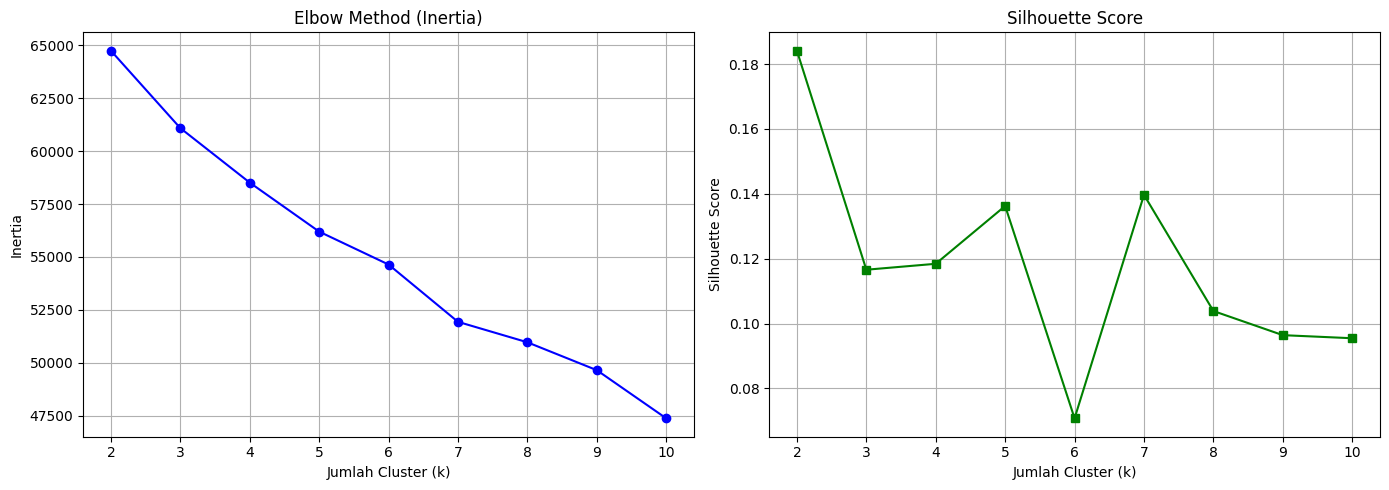

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Menyiapkan list untuk menampung inertia dan silhouette score
inertia = []
silhouette_scores = []
K_range = range(2, 11) # Mencoba jumlah cluster dari 2 sampai 10

for k in K_range:
    # Inisialisasi KMeans
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)

    # Simpan inertia
    inertia.append(kmeans.inertia_)

    # Simpan silhouette score
    score = silhouette_score(df_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# Membuat plot untuk Elbow Method dan Silhouette Score
plt.figure(figsize=(14, 5))

# Plot Elbow Method (Inertia)
plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o', color='b', linestyle='-')
plt.title('Elbow Method (Inertia)')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.grid(True)

# Plot Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='s', color='g', linestyle='-')
plt.title('Silhouette Score')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)

plt.tight_layout()
plt.show()

# Step 8: Pilih k optimal dan klasterisasi

In [10]:
# Menentukan jumlah cluster optimal (misal k = 4)
optimal_k = 4

# Inisialisasi dan fitting KMeans dengan k optimal
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_final.fit(df_scaled)

# Menambahkan kolom label cluster ke dataframe asli (df) dan df_final
df['Cluster'] = kmeans_final.labels_
df_final['Cluster'] = kmeans_final.labels_

# Menampilkan jumlah data pada masing-masing cluster
print(f"Distribusi data pada tiap cluster (k={optimal_k}):")
print(df['Cluster'].value_counts())

Distribusi data pada tiap cluster (k=4):
Cluster
0    1002
2     612
1     454
3     172
Name: count, dtype: int64


# Step 9: Visualisasi klaster dengan PCA 2D

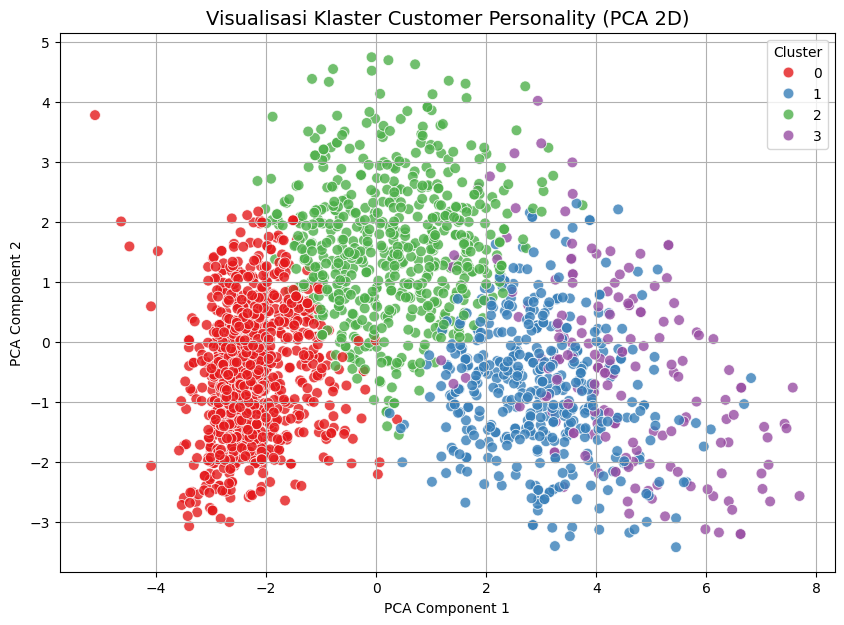

In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Reduksi dimensi data scaled dari 36 kolom menjadi 2 komponen utama (PCA)
pca = PCA(n_components=2, random_state=42)
df_pca = pca.fit_transform(df_scaled)

# 2. Membuat DataFrame hasil PCA beserta label clusternya
df_pca_vis = pd.DataFrame(df_pca, columns=['PCA1', 'PCA2'])
df_pca_vis['Cluster'] = df['Cluster'].values

# 3. Plot hasil visualisasi cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PCA1', y='PCA2',
    hue='Cluster',
    data=df_pca_vis,
    palette='Set1',
    s=60,
    alpha=0.8
)

plt.title('Visualisasi Klaster Customer Personality (PCA 2D)', fontsize=14)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

# Step 10: Profiling cluster (rata-rata fitur per cluster)

Profiling cluster (rata-rata fitur per cluster), kita bisa melihat karakteristik atau kebiasaan dari setiap klaster pelanggan yang sudah terbentuk (misalnya melihat rata-rata pendapatan, jumlah pembelian lewat web/toko, atau pembelian produk seperti Wines dan Meat di setiap klaster).

In [12]:
# Menghitung rata-rata (mean) dari setiap kolom numerik berdasarkan Cluster
cluster_profile = df.groupby('Cluster').mean(numeric_only=True)

# Menampilkan hasil profiling untuk beberapa fitur utama (misal: Income, MntWines, MntMeatProducts, dll)
print("Profil Rata-rata Tiap Cluster:")
key_features = ['Income', 'MntWines', 'MntMeatProducts', 'NumWebPurchases', 'NumStorePurchases', 'Recency']
display(cluster_profile[key_features])

Profil Rata-rata Tiap Cluster:


,Income,MntWines,MntMeatProducts,NumWebPurchases,NumStorePurchases,Recency
Cluster,,,,,,
0,34422.632500,37.622754,22.285429,2.057884,3.133733,49.240519
1,74034.995607,491.048458,428.462555,5.244493,8.407489,49.431718
2,57033.163006,440.348039,125.436275,6.168301,7.511438,48.424837
3,81547.566876,876.098837,467.145349,5.418605,8.232558,49.930233


# Simpulkan Analisa dari hasil

Kesimpulan & Profil Klaster Pelanggan ($k = 4$):



1.   Klaster 0: **Pelanggan Ekonomi / Anggaran
Terbatas (Budget Customers)**
- **Karakteristik**: Memiliki rata-rata pendapatan yang paling rendah ($\approx \$34,422$) dengan tingkat pengeluaran untuk semua jenis produk (seperti Wine dan Meat) yang sangat kecil. Aktivitas belanja mereka melalui web maupun toko fisik juga tergolong rendah.
- **Strategi**: Cocok diberi penawaran produk ekonomis, diskon besar, atau kupon promo (deals) untuk menarik minat belanja mereka.

2.   Klaster 1: **Pelanggan Premium / Kelas Atas (High-Value Spenders)**
- **Karakteristik**: Memiliki pendapatan tinggi ($\approx \$74,034$) serta tingkat pembelian yang tinggi, terutama pada produk Wine ($\approx 491$) dan Meat ($\approx 428$). Mereka juga sangat aktif berbelanja langsung di toko fisik (Store Purchases tinggi).
- **Strategi**: Pertahankan loyalitas mereka dengan memberikan layanan VIP, penawaran produk eksklusif, atau program membership khusus.

3. Klaster 2: **Pelanggan Digital / Aktif Berbelanja Online (Modern / Web-Oriented Shoppers)**
- **Karakteristik**: Memiliki pendapatan kelas menengah ke atas ($\approx \$57,033$). Klaster ini menonjol karena memiliki jumlah transaksi melalui web (NumWebPurchases) yang paling tinggi dibandingkan klaster lainnya, serta tetap aktif berbelanja di toko fisik.
- **Strategi**: Maksimalkan pemasaran digital melalui email marketing, rekomendasi produk berbasis web, dan kemudahan pengalaman berbelanja di platform online/aplikasi.

4. Klaster 3: **Pelanggan Loyal VIP / Top Spenders (Elite Customers)**

- **Karakteristik**: Merupakan kelompok dengan rata-rata pendapatan tertinggi ($\approx \$81,547$) dan pengeluaran terbesar secara keseluruhan, terutama sangat mendominasi pembelian Wine ($\approx 876$) dan daging (Meat $\approx 467$). Meskipun jumlah pelanggannya paling sedikit, kontribusi nilai belanjanya sangat besar.
- **Strategi**: Berikan pelayanan yang sangat personal (personalized marketing), penawaran produk luxury atau edisi terbatas, serta keistimewaan khusus untuk menjaga kepuasan mereka.